# Updated evaluation — 9 November 2026

    **Checkpoint:** `real_abc_balanced_optional_space_20261108/checkpoint_best.pt`  
    **Matcher:** independent, disjoint passages; gap fragments; visual-confidence floor; corroborated short regions.

    **Reload/reopen this notebook from disk first, then restart the kernel. A kernel restart alone does not reload edited cells.**

    The previous settings rejected your separated-word example: 556 candidates failed support, 170 failed density, and 2 failed anchors. Reversed-order passages also faced an explicit global ordering restriction. Each passage now keeps its internal order, while separate passages may swap order without reusing their window spans.

    ## Quantitative results on the same fixed cohort

    32 saved-test positives + 100 seeded presumed-negative comparisons. The inspected example was excluded from headline test scores. Two duplicated validation images were quarantined; settings were selected using 147 validation positives and 98 presumed negatives.

    | Method | Mask IoU | Dice | Precision | Recall | False detections |
    | --- | ---: | ---: | ---: | ---: | ---: |
    | Previous weights, old settings* | 21.18% | 26.06% | 25.46% | 35.86% | 18/100 |
| Current weights, old settings | 51.03% | 56.40% | 62.65% | 55.21% | 3/100 |
| Current weights, validation-selected matcher | 62.63% | 67.76% | 65.95% | 70.81% | 8/100 |

    **Trade-off:** IoU improves from **51.0% to 62.6%** and recall from **55.2% to 70.8%**, while presumed-negative false detections rise from **3/100 to 8/100**. The validation FPR was 4/98; the 5% validation limit did not transfer to test.

    *The previous-checkpoint reference includes recorded training exposure in 60/132 pairs. The checkpoints share no saved-test positive pairs, so this is a descriptive weight comparison.*

    [Full report and all metrics](../docs/reordered_regions_evaluation.md) · [Metric JSON](../docs/evaluation/reordered_regions_20261109/metrics.json) · [Per-pair scores](../docs/evaluation/reordered_regions_20261109/per_pair.csv)

    ## Your supplied example remains a partial result

    `alignedPairs:pair_000028__A_line_005__B_line_002` has three supplied common fragments: “ابتغاء”, “الله”, and “من”, in the same order. The selected matcher returns **two regions instead of zero**, but mean mask IoU is only **21.9%**. The third fragment and exact correspondence are not fully recovered. The before/after figures show supplied ground truth beside the predictions; they are not claims of complete recovery.

    The synthetic reversed-passage figure separately demonstrates the structural order fix. It is an algorithm regression, **not measured model performance**.
    

## Real reordered passages: separate training-pair illustration

`pair_000001__A_line_011__B_line_005` changes from 1 accepted region to 2, with mask IoU 52.4% → 87.1%. The annotated shared fragments occur in different orders. **Both source lines are training members**; this illustrates the structural fix and is not an extra held-out score. All matching settings were already frozen.

# A–B, B–C and A–C qualitative review
15 selected examples: 5 per book pair.
Checkpoint: `Weights/real_abc_balanced_optional_space_20261108/checkpoint_best.pt`.
Matching parameters from `notebooks/model_evaluation.ipynb`; representation=`fused`, crop=`content`, device=`mps`.
Same fixed examples as the original review, selected using the previous checkpoint. They have not been selected or ranked using the current checkpoint. Current checkpoint split membership is recorded per sample, including training and validation lines. Unseen means absent from this checkpoint split manifest, not necessarily from earlier training. This mixed-split qualitative comparison is not a held-out performance estimate.
Examples are selected for agreement with the supplied masks on both lines.
Saved outputs come from `scripts/eval/review_book_pairs.py`; no training or parameter search.


In [ ]:
from pathlib import Path
import json
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'evaluation_utils.py').is_file())
REVIEW = ROOT / 'Results/Evaluation/reordered_regions_20261109/fixed_examples'
REPORT = json.loads((REVIEW / 'report.json').read_text())
print('Matching parameters from:', Path(REPORT['settings_source']['path']).relative_to(ROOT))
print(json.dumps(REPORT['settings'], indent=2))


Matching parameters from: notebooks/model_evaluation.ipynb
{
  "similarity_mode": "letter_evidence",
  "decoder": "local_repeat_dtw",
  "threshold": 0.5,
  "contrast_margin": 0.05,
  "score_mode": "background",
  "min_windows": 3,
  "max_gap": 4,
  "gap_open": 0.5940936607241908,
  "gap_extend": 0.5826132317598225,
  "max_candidates": 512,
  "repeat_penalty": 0.2,
  "max_stretch": 3,
  "acceptance_offset": 0.1,
  "prior_floor": 0.0001,
  "alignment_mode": "local_repeat_dtw",
  "max_consecutive_repeats": 2,
  "min_distinct_windows_a": 3,
  "min_distinct_windows_b": 3,
  "min_matched_pairs": 4,
  "use_strong_start_anchor": false,
  "start_top_k": 3,
  "start_min_reward": null,
  "min_region_score": null,
  "min_mean_reward": 0.0,
  "min_path_density": 0.85,
  "max_repeat_fraction": null,
  "min_secondary_score_ratio": null,
  "window_match_temperature": 0.1,
  "window_match_min_cosine": 0.5,
  "window_match_reward_offset": 0.0,
  "use_path_anchor_check": true,
  "anchor_top_k": 4,
  "min

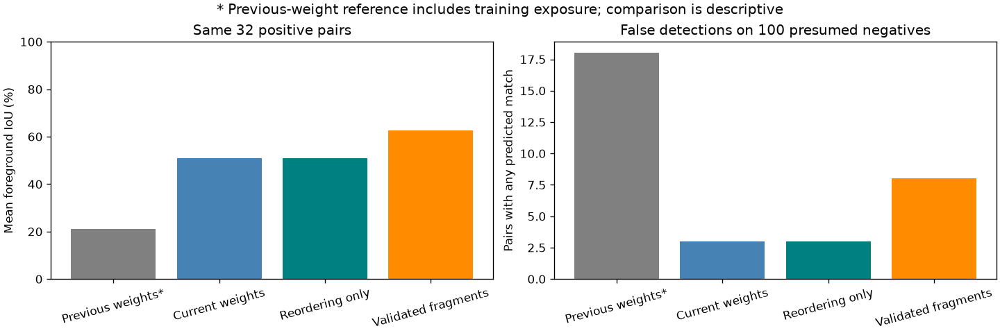

In [ ]:
# Measured mask localization and false detections
from pathlib import Path
from IPython.display import Image, display
_review_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'evaluation_utils.py').is_file())
_review_figure = _review_root / 'Results/Evaluation/reordered_regions_20261109/quantitative_comparison.png'
if _review_figure.is_file():
    display(Image(filename=str(_review_figure)))
else:
    print('The saved notebook contains this figure. To regenerate local artifacts, run scripts/eval/review_reordered.py followed by scripts/eval/render_reordered_report.py --update-notebooks.')

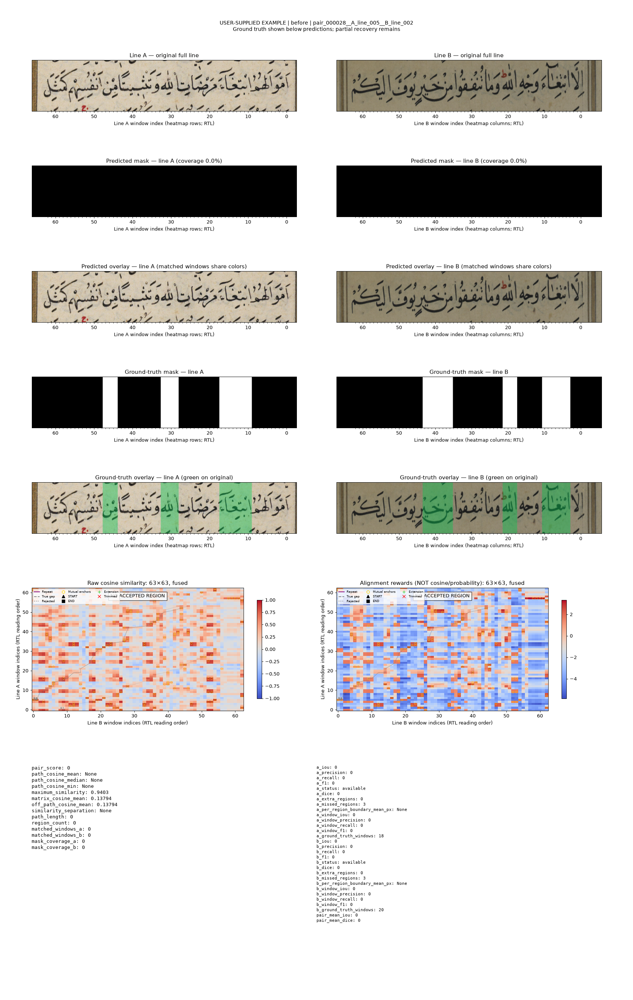

In [ ]:
# Supplied example: previous settings, no accepted region
from pathlib import Path
from IPython.display import Image, display
_review_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'evaluation_utils.py').is_file())
_review_figure = _review_root / 'Results/Evaluation/reordered_regions_20261109/user_example_before.png'
if _review_figure.is_file():
    display(Image(filename=str(_review_figure)))
else:
    print('The saved notebook contains this figure. To regenerate local artifacts, run scripts/eval/review_reordered.py followed by scripts/eval/render_reordered_report.py --update-notebooks.')

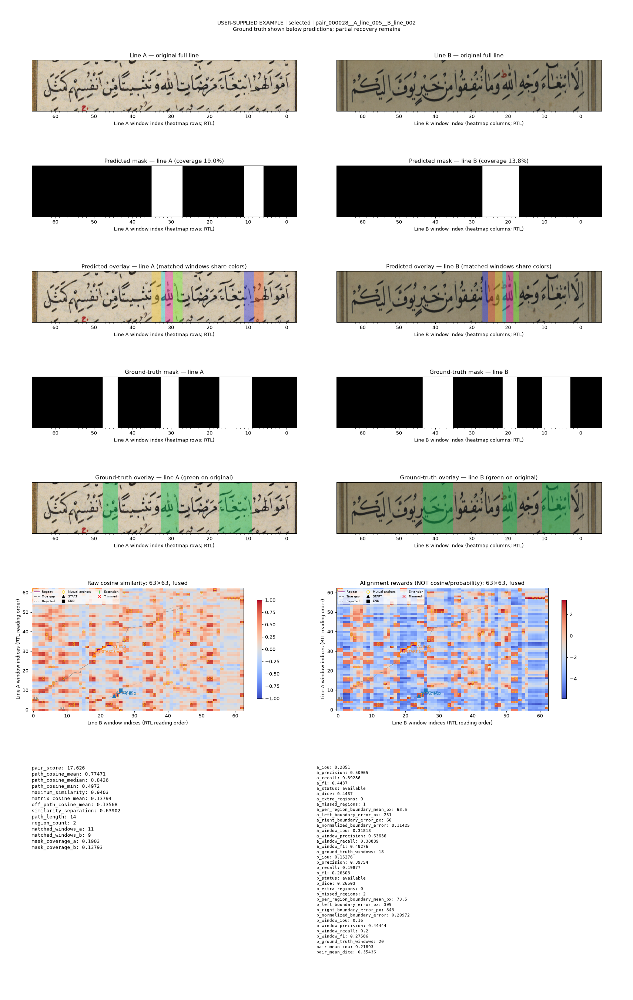

In [ ]:
# Supplied example: selected settings, partial recovery
from pathlib import Path
from IPython.display import Image, display
_review_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'evaluation_utils.py').is_file())
_review_figure = _review_root / 'Results/Evaluation/reordered_regions_20261109/user_example_selected.png'
if _review_figure.is_file():
    display(Image(filename=str(_review_figure)))
else:
    print('The saved notebook contains this figure. To regenerate local artifacts, run scripts/eval/review_reordered.py followed by scripts/eval/render_reordered_report.py --update-notebooks.')

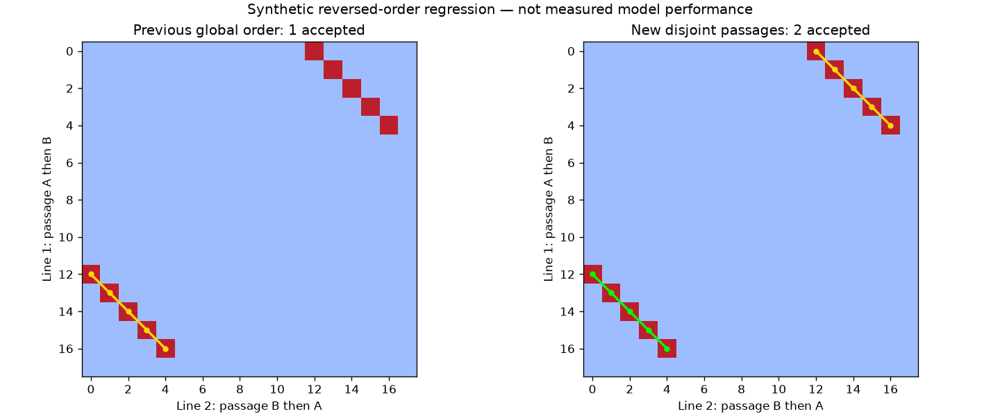

In [ ]:
# Synthetic reversed-passage regression
from pathlib import Path
from IPython.display import Image, display
_review_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'evaluation_utils.py').is_file())
_review_figure = _review_root / 'Results/Evaluation/reordered_regions_20261109/reversed_order_regression.png'
if _review_figure.is_file():
    display(Image(filename=str(_review_figure)))
else:
    print('The saved notebook contains this figure. To regenerate local artifacts, run scripts/eval/review_reordered.py followed by scripts/eval/render_reordered_report.py --update-notebooks.')

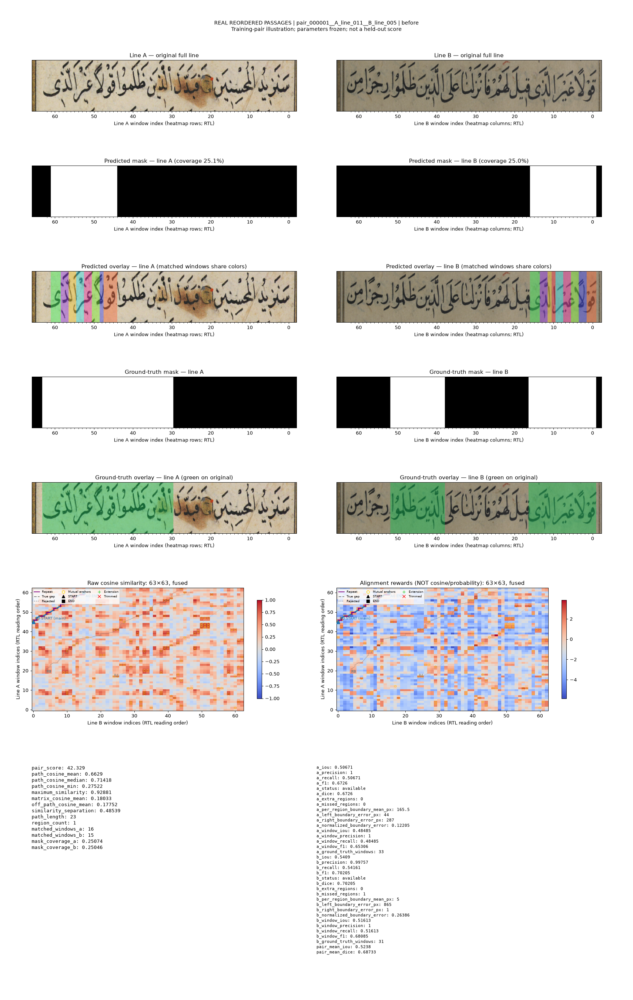

In [ ]:
# Real reordered passages before the order fix (training-pair illustration)
from pathlib import Path
from IPython.display import Image, display
_review_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'evaluation_utils.py').is_file())
_review_figure = _review_root / 'Results/Evaluation/reordered_regions_20261109/real_reordered_before.png'
if _review_figure.is_file():
    display(Image(filename=str(_review_figure)))
else:
    print('The saved notebook contains this figure. To regenerate local artifacts, run scripts/eval/review_reordered.py followed by scripts/eval/render_reordered_report.py --update-notebooks.')

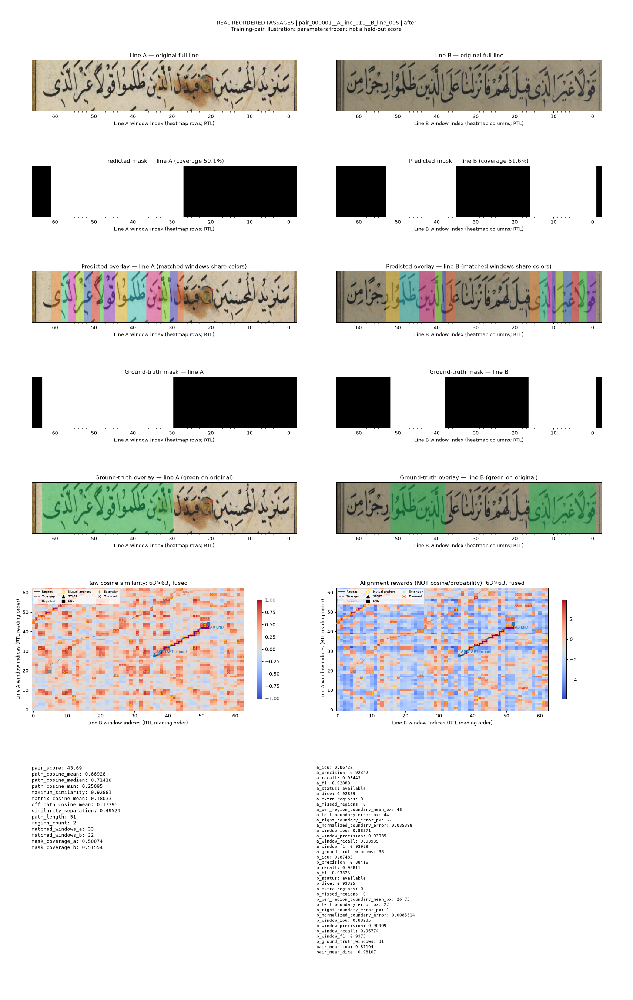

In [ ]:
# Real reordered passages after the order fix (training-pair illustration)
from pathlib import Path
from IPython.display import Image, display
_review_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'evaluation_utils.py').is_file())
_review_figure = _review_root / 'Results/Evaluation/reordered_regions_20261109/real_reordered_after.png'
if _review_figure.is_file():
    display(Image(filename=str(_review_figure)))
else:
    print('The saved notebook contains this figure. To regenerate local artifacts, run scripts/eval/review_reordered.py followed by scripts/eval/render_reordered_report.py --update-notebooks.')

A_B_example_01 | physical books A/B (plot rows A/B) | splits: A=train, B=train
IoU: A=0.817, B=0.816; accepted routes=2
Mean mask IoU=0.817
White-mask precision: A=0.822, B=0.816; recall: A=0.993, B=1.000
Predicted white coverage: A=35.8%, B=36.1%
Black-background specificity: A=0.909, B=0.906
White F2 (recall priority): A=0.953, B=0.957


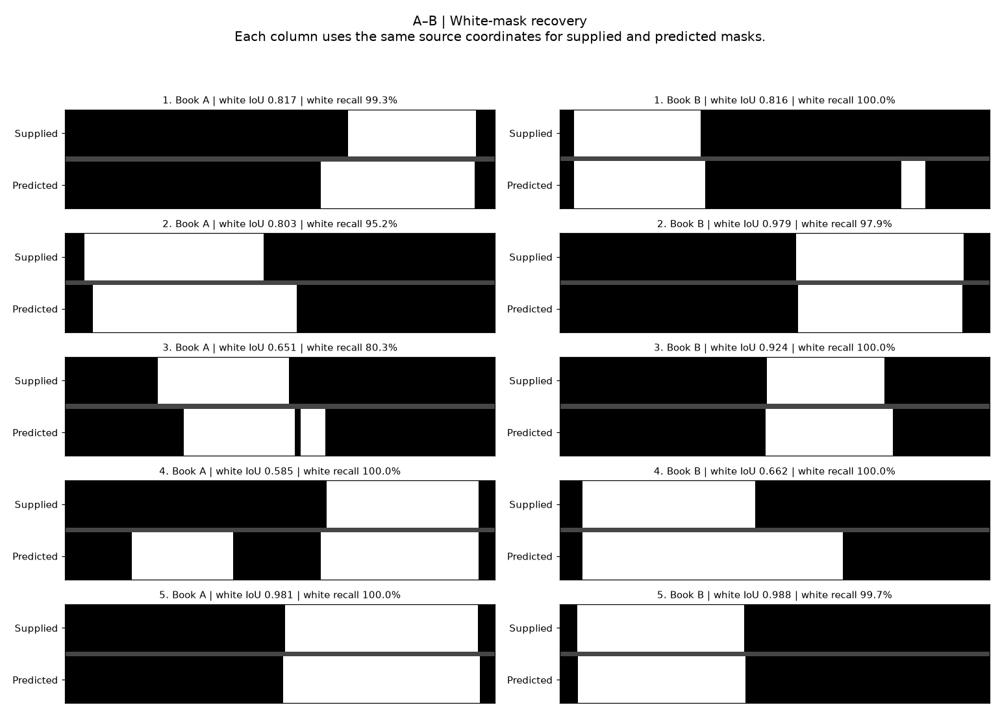

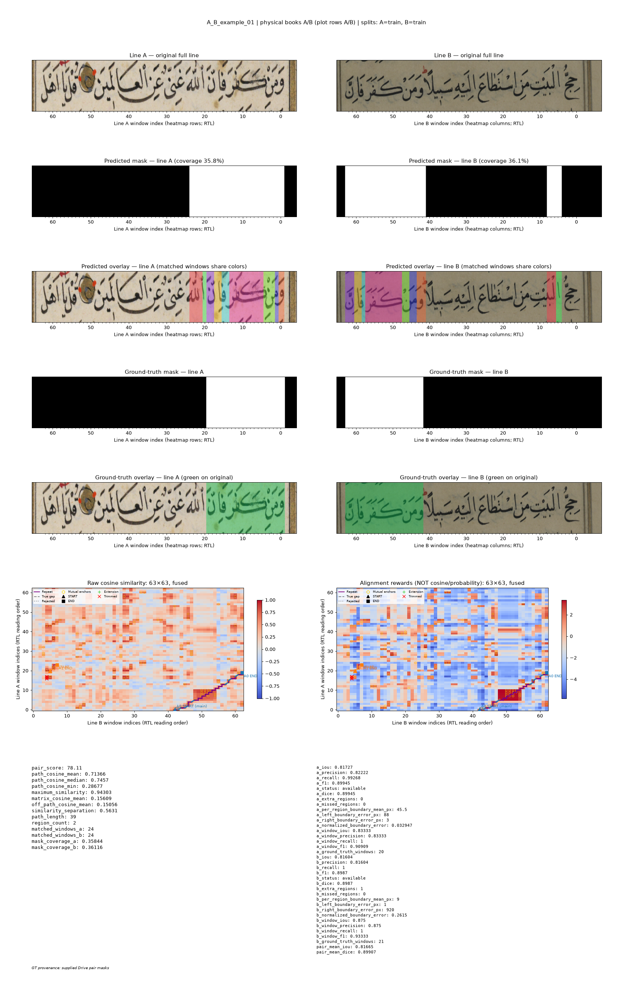

In [ ]:
from IPython.display import Image, display
print('A_B_example_01 | physical books A/B (plot rows A/B) | splits: A=train, B=train\nIoU: A=0.817, B=0.816; accepted routes=2\nMean mask IoU=0.817\nWhite-mask precision: A=0.822, B=0.816; recall: A=0.993, B=1.000\nPredicted white coverage: A=35.8%, B=36.1%\nBlack-background specificity: A=0.909, B=0.906\nWhite F2 (recall priority): A=0.953, B=0.957')
display(Image(filename=str(REVIEW / 'white_masks_A_B.png')))
display(Image(filename=str(REVIEW / 'A_B_example_01.png')))


A_B_example_02 | physical books A/B (plot rows A/B) | splits: A=train, B=train
IoU: A=0.803, B=0.979; accepted routes=1
Mean mask IoU=0.891
White-mask precision: A=0.837, B=1.000; recall: A=0.952, B=0.979
Predicted white coverage: A=47.5%, B=38.1%
Black-background specificity: A=0.867, B=1.000
White F2 (recall priority): A=0.927, B=0.983


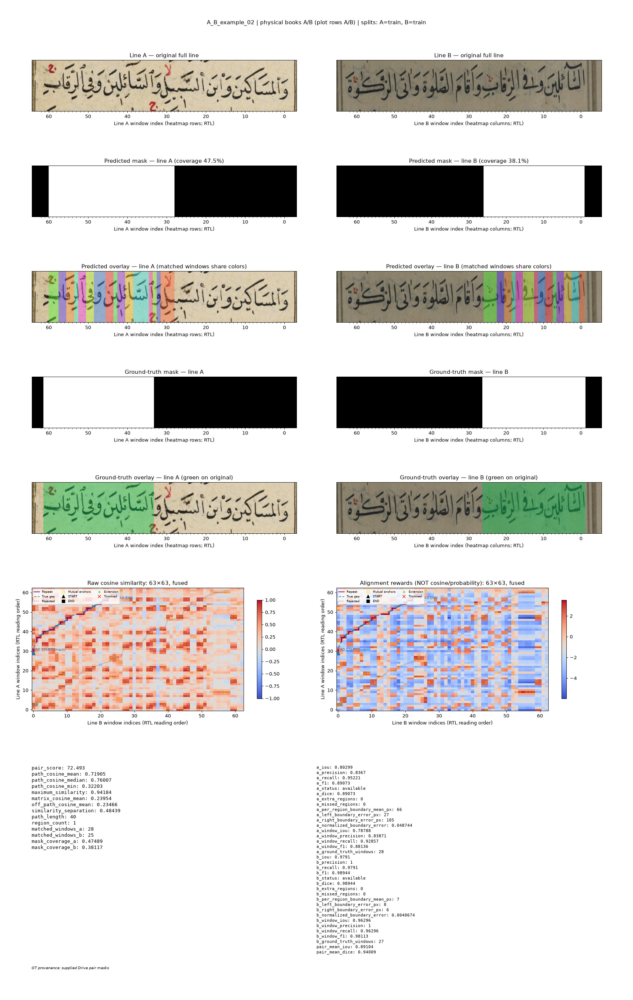

In [ ]:
from IPython.display import Image, display
print('A_B_example_02 | physical books A/B (plot rows A/B) | splits: A=train, B=train\nIoU: A=0.803, B=0.979; accepted routes=1\nMean mask IoU=0.891\nWhite-mask precision: A=0.837, B=1.000; recall: A=0.952, B=0.979\nPredicted white coverage: A=47.5%, B=38.1%\nBlack-background specificity: A=0.867, B=1.000\nWhite F2 (recall priority): A=0.927, B=0.983')
display(Image(filename=str(REVIEW / 'A_B_example_02.png')))


A_B_example_03 | physical books A/B (plot rows A/B) | splits: A=train, B=train
IoU: A=0.651, B=0.924; accepted routes=2
Mean mask IoU=0.788
White-mask precision: A=0.775, B=0.924; recall: A=0.803, B=1.000
Predicted white coverage: A=31.7%, B=29.6%
Black-background specificity: A=0.897, B=0.969
White F2 (recall priority): A=0.797, B=0.984


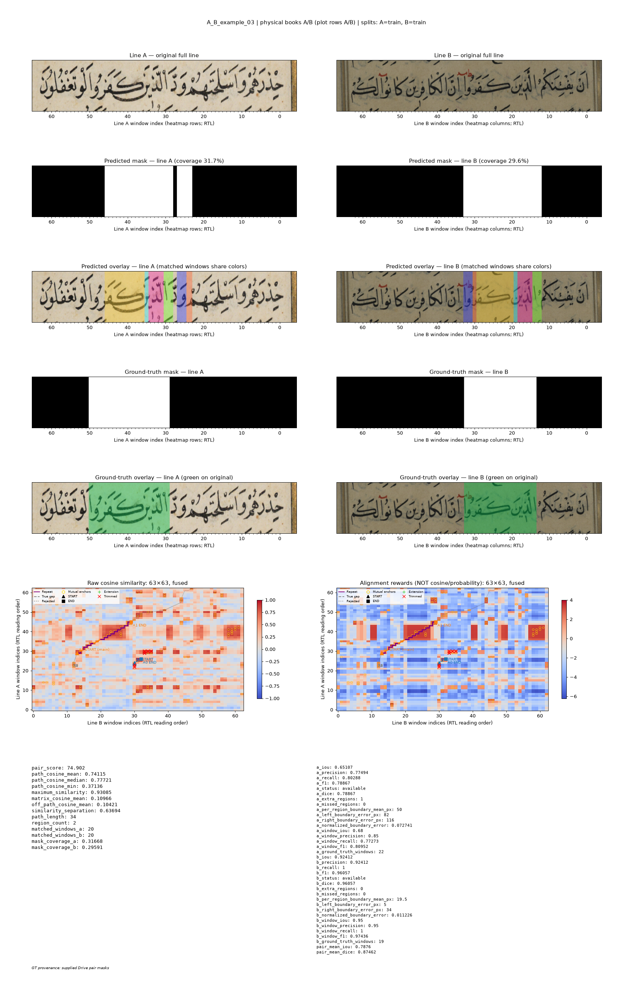

In [ ]:
from IPython.display import Image, display
print('A_B_example_03 | physical books A/B (plot rows A/B) | splits: A=train, B=train\nIoU: A=0.651, B=0.924; accepted routes=2\nMean mask IoU=0.788\nWhite-mask precision: A=0.775, B=0.924; recall: A=0.803, B=1.000\nPredicted white coverage: A=31.7%, B=29.6%\nBlack-background specificity: A=0.897, B=0.969\nWhite F2 (recall priority): A=0.797, B=0.984')
display(Image(filename=str(REVIEW / 'A_B_example_03.png')))


A_B_example_04 | physical books A/B (plot rows A/B) | splits: A=unseen, B=train
IoU: A=0.585, B=0.662; accepted routes=2
Mean mask IoU=0.623
White-mask precision: A=0.585, B=0.662; recall: A=1.000, B=1.000
Predicted white coverage: A=60.3%, B=60.7%
Black-background specificity: A=0.613, B=0.657
White F2 (recall priority): A=0.876, B=0.907


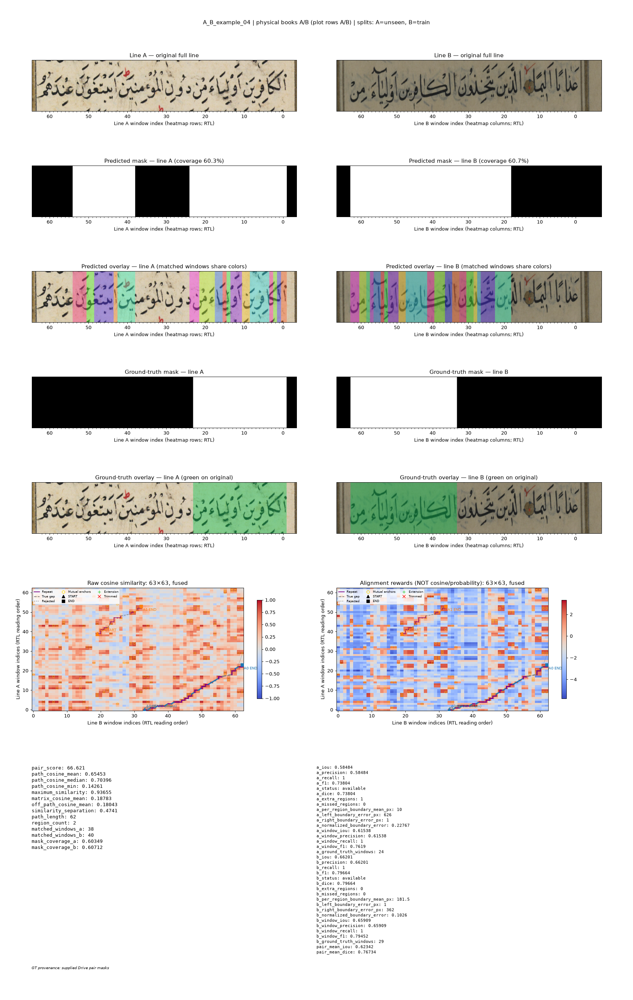

In [ ]:
from IPython.display import Image, display
print('A_B_example_04 | physical books A/B (plot rows A/B) | splits: A=unseen, B=train\nIoU: A=0.585, B=0.662; accepted routes=2\nMean mask IoU=0.623\nWhite-mask precision: A=0.585, B=0.662; recall: A=1.000, B=1.000\nPredicted white coverage: A=60.3%, B=60.7%\nBlack-background specificity: A=0.613, B=0.657\nWhite F2 (recall priority): A=0.876, B=0.907')
display(Image(filename=str(REVIEW / 'A_B_example_04.png')))


A_B_example_05 | physical books A/B (plot rows A/B) | splits: A=val, B=val
IoU: A=0.981, B=0.988; accepted routes=1
Mean mask IoU=0.984
White-mask precision: A=0.981, B=0.991; recall: A=1.000, B=0.997
Predicted white coverage: A=45.8%, B=39.1%
Black-background specificity: A=0.984, B=0.994
White F2 (recall priority): A=0.996, B=0.996


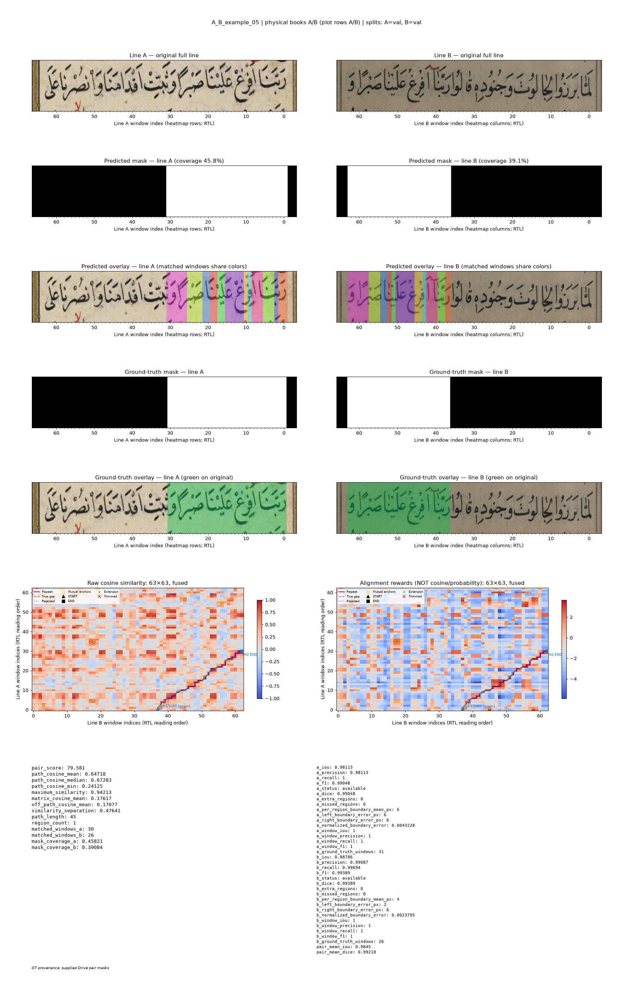

In [ ]:
from IPython.display import Image, display
print('A_B_example_05 | physical books A/B (plot rows A/B) | splits: A=val, B=val\nIoU: A=0.981, B=0.988; accepted routes=1\nMean mask IoU=0.984\nWhite-mask precision: A=0.981, B=0.991; recall: A=1.000, B=0.997\nPredicted white coverage: A=45.8%, B=39.1%\nBlack-background specificity: A=0.984, B=0.994\nWhite F2 (recall priority): A=0.996, B=0.996')
display(Image(filename=str(REVIEW / 'A_B_example_05.png')))


A_C_example_01 | physical books A/C (plot rows A/B) | splits: A=unseen, C=train
IoU: A=0.000, C=0.000; accepted routes=0
Mean mask IoU=0.000
White-mask precision: A=0.000, C=0.000; recall: A=0.000, C=0.000
Predicted white coverage: A=0.0%, C=0.0%
Black-background specificity: A=1.000, C=1.000
White F2 (recall priority): A=0.000, C=0.000


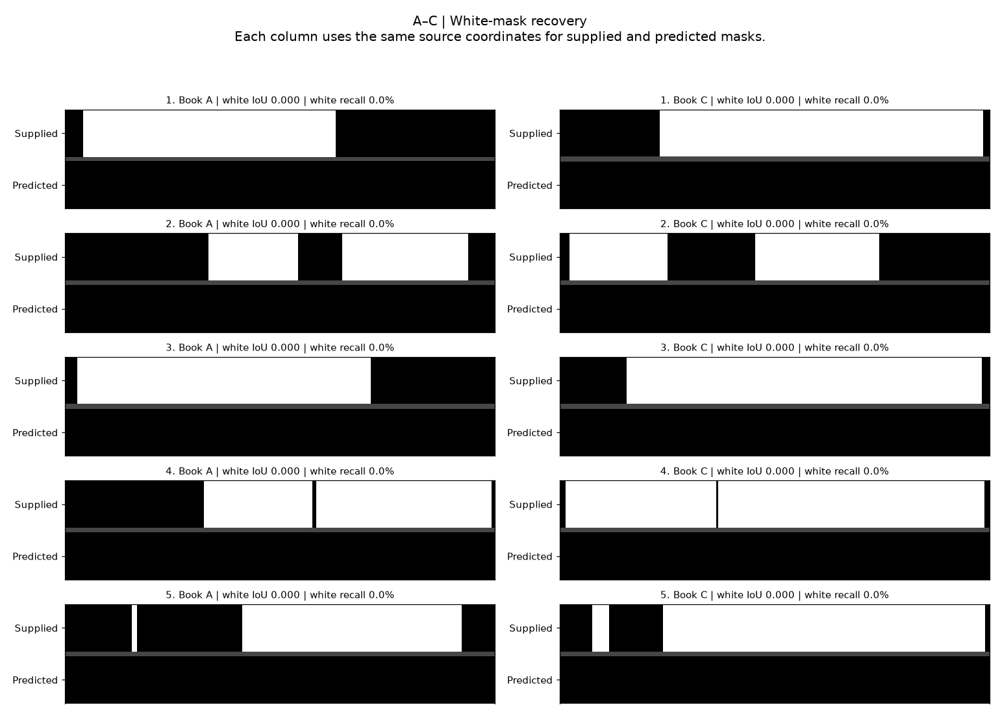

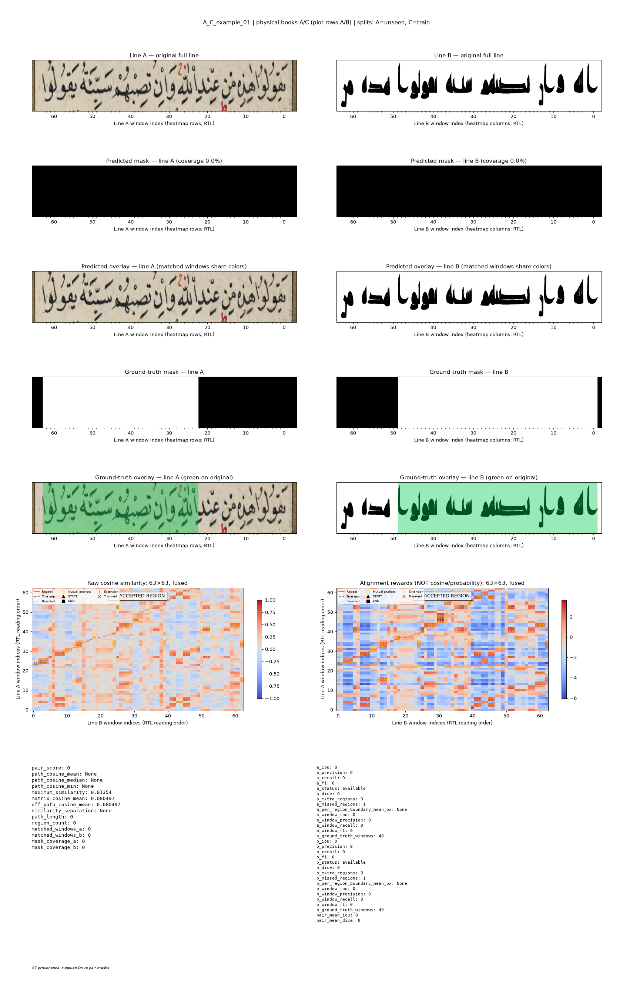

In [ ]:
from IPython.display import Image, display
print('A_C_example_01 | physical books A/C (plot rows A/B) | splits: A=unseen, C=train\nIoU: A=0.000, C=0.000; accepted routes=0\nMean mask IoU=0.000\nWhite-mask precision: A=0.000, C=0.000; recall: A=0.000, C=0.000\nPredicted white coverage: A=0.0%, C=0.0%\nBlack-background specificity: A=1.000, C=1.000\nWhite F2 (recall priority): A=0.000, C=0.000')
display(Image(filename=str(REVIEW / 'white_masks_A_C.png')))
display(Image(filename=str(REVIEW / 'A_C_example_01.png')))


A_C_example_02 | physical books A/C (plot rows A/B) | splits: A=unseen, C=train
IoU: A=0.000, C=0.000; accepted routes=0
Mean mask IoU=0.000
White-mask precision: A=0.000, C=0.000; recall: A=0.000, C=0.000
Predicted white coverage: A=0.0%, C=0.0%
Black-background specificity: A=1.000, C=1.000
White F2 (recall priority): A=0.000, C=0.000


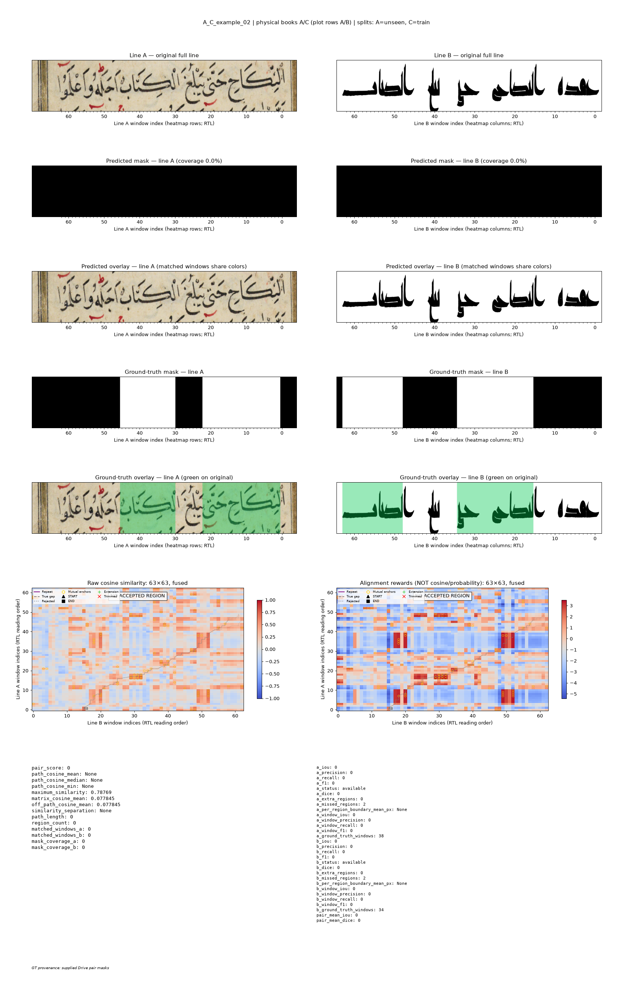

In [ ]:
from IPython.display import Image, display
print('A_C_example_02 | physical books A/C (plot rows A/B) | splits: A=unseen, C=train\nIoU: A=0.000, C=0.000; accepted routes=0\nMean mask IoU=0.000\nWhite-mask precision: A=0.000, C=0.000; recall: A=0.000, C=0.000\nPredicted white coverage: A=0.0%, C=0.0%\nBlack-background specificity: A=1.000, C=1.000\nWhite F2 (recall priority): A=0.000, C=0.000')
display(Image(filename=str(REVIEW / 'A_C_example_02.png')))


A_C_example_03 | physical books A/C (plot rows A/B) | splits: A=train, C=train
IoU: A=0.000, C=0.000; accepted routes=0
Mean mask IoU=0.000
White-mask precision: A=0.000, C=0.000; recall: A=0.000, C=0.000
Predicted white coverage: A=0.0%, C=0.0%
Black-background specificity: A=1.000, C=1.000
White F2 (recall priority): A=0.000, C=0.000


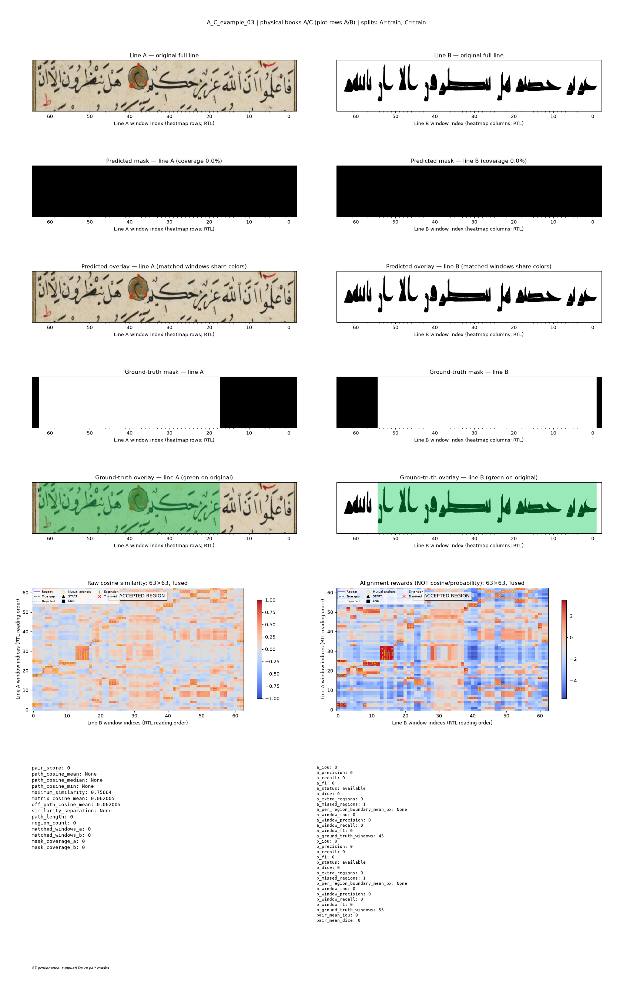

In [ ]:
from IPython.display import Image, display
print('A_C_example_03 | physical books A/C (plot rows A/B) | splits: A=train, C=train\nIoU: A=0.000, C=0.000; accepted routes=0\nMean mask IoU=0.000\nWhite-mask precision: A=0.000, C=0.000; recall: A=0.000, C=0.000\nPredicted white coverage: A=0.0%, C=0.0%\nBlack-background specificity: A=1.000, C=1.000\nWhite F2 (recall priority): A=0.000, C=0.000')
display(Image(filename=str(REVIEW / 'A_C_example_03.png')))


A_C_example_04 | physical books A/C (plot rows A/B) | splits: A=train, C=unseen
IoU: A=0.000, C=0.000; accepted routes=0
Mean mask IoU=0.000
White-mask precision: A=0.000, C=0.000; recall: A=0.000, C=0.000
Predicted white coverage: A=0.0%, C=0.0%
Black-background specificity: A=1.000, C=1.000
White F2 (recall priority): A=0.000, C=0.000


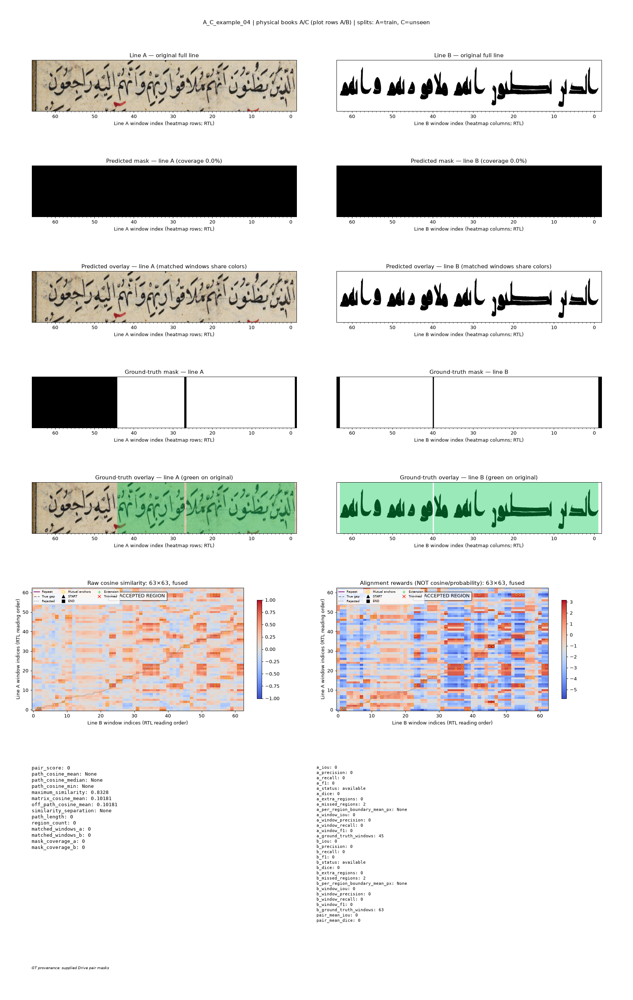

In [ ]:
from IPython.display import Image, display
print('A_C_example_04 | physical books A/C (plot rows A/B) | splits: A=train, C=unseen\nIoU: A=0.000, C=0.000; accepted routes=0\nMean mask IoU=0.000\nWhite-mask precision: A=0.000, C=0.000; recall: A=0.000, C=0.000\nPredicted white coverage: A=0.0%, C=0.0%\nBlack-background specificity: A=1.000, C=1.000\nWhite F2 (recall priority): A=0.000, C=0.000')
display(Image(filename=str(REVIEW / 'A_C_example_04.png')))


A_C_example_05 | physical books A/C (plot rows A/B) | splits: A=train, C=unseen
IoU: A=0.000, C=0.000; accepted routes=0
Mean mask IoU=0.000
White-mask precision: A=0.000, C=0.000; recall: A=0.000, C=0.000
Predicted white coverage: A=0.0%, C=0.0%
Black-background specificity: A=1.000, C=1.000
White F2 (recall priority): A=0.000, C=0.000


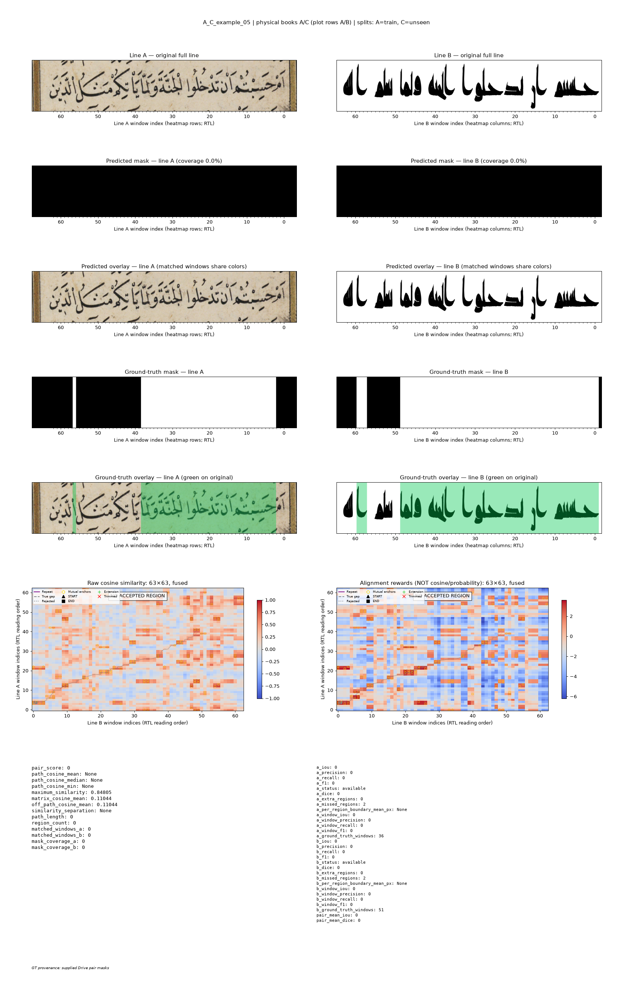

In [ ]:
from IPython.display import Image, display
print('A_C_example_05 | physical books A/C (plot rows A/B) | splits: A=train, C=unseen\nIoU: A=0.000, C=0.000; accepted routes=0\nMean mask IoU=0.000\nWhite-mask precision: A=0.000, C=0.000; recall: A=0.000, C=0.000\nPredicted white coverage: A=0.0%, C=0.0%\nBlack-background specificity: A=1.000, C=1.000\nWhite F2 (recall priority): A=0.000, C=0.000')
display(Image(filename=str(REVIEW / 'A_C_example_05.png')))


B_C_example_01 | physical books B/C (plot rows A/B) | splits: B=train, C=unseen
IoU: B=0.962, C=0.972; accepted routes=1
Mean mask IoU=0.967
White-mask precision: B=0.989, C=0.972; recall: B=0.972, C=1.000
Predicted white coverage: B=50.9%, C=76.7%
Black-background specificity: B=0.989, C=0.916
White F2 (recall priority): B=0.976, C=0.994


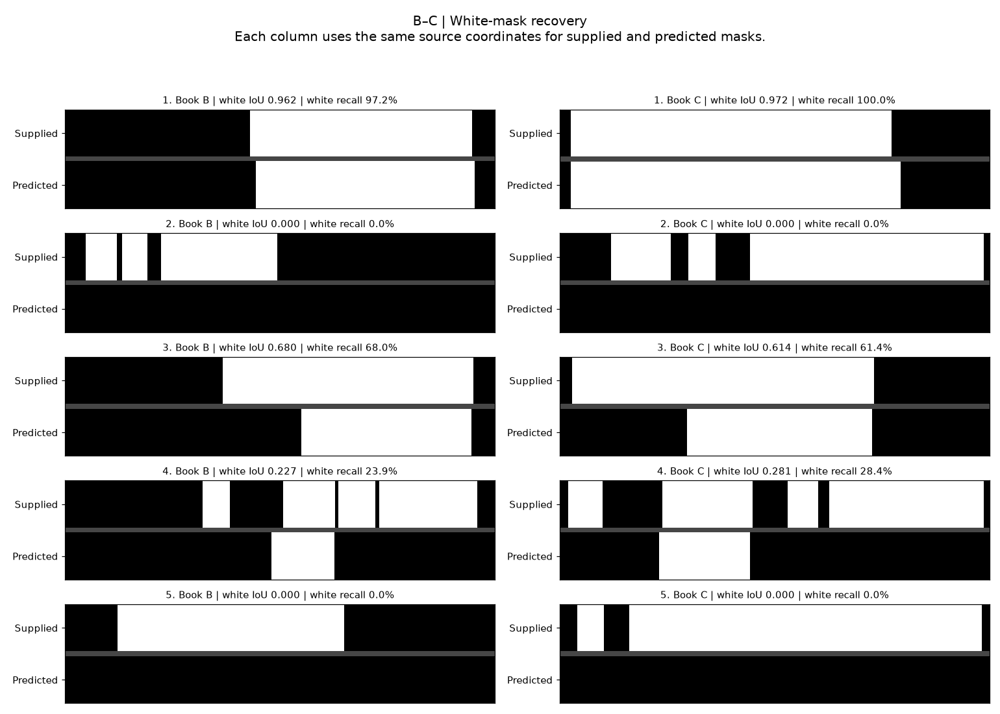

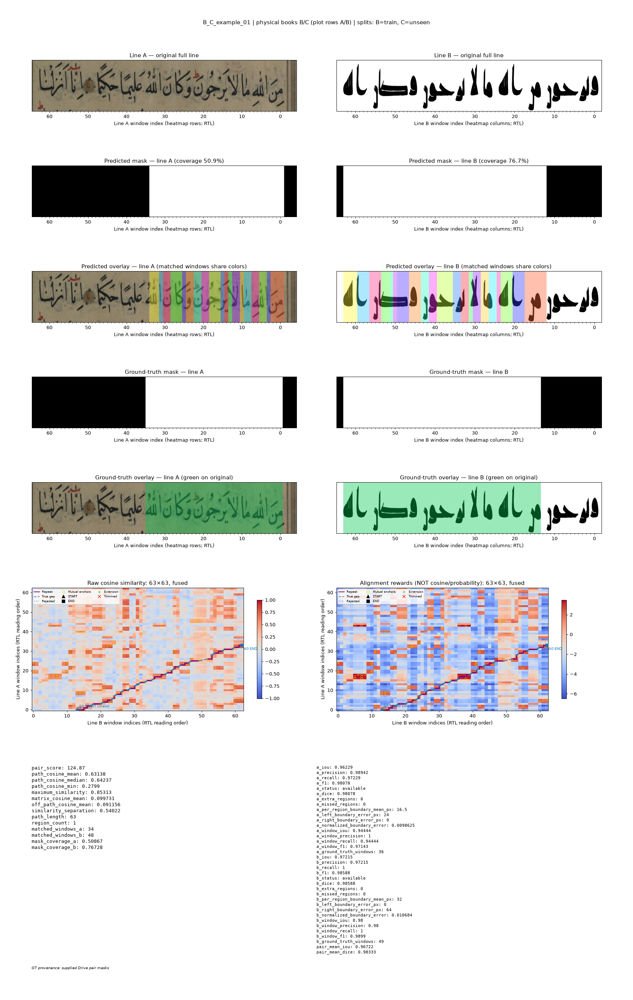

In [ ]:
from IPython.display import Image, display
print('B_C_example_01 | physical books B/C (plot rows A/B) | splits: B=train, C=unseen\nIoU: B=0.962, C=0.972; accepted routes=1\nMean mask IoU=0.967\nWhite-mask precision: B=0.989, C=0.972; recall: B=0.972, C=1.000\nPredicted white coverage: B=50.9%, C=76.7%\nBlack-background specificity: B=0.989, C=0.916\nWhite F2 (recall priority): B=0.976, C=0.994')
display(Image(filename=str(REVIEW / 'white_masks_B_C.png')))
display(Image(filename=str(REVIEW / 'B_C_example_01.png')))


B_C_example_02 | physical books B/C (plot rows A/B) | splits: B=train, C=unseen
IoU: B=0.000, C=0.000; accepted routes=0
Mean mask IoU=0.000
White-mask precision: B=0.000, C=0.000; recall: B=0.000, C=0.000
Predicted white coverage: B=0.0%, C=0.0%
Black-background specificity: B=1.000, C=1.000
White F2 (recall priority): B=0.000, C=0.000


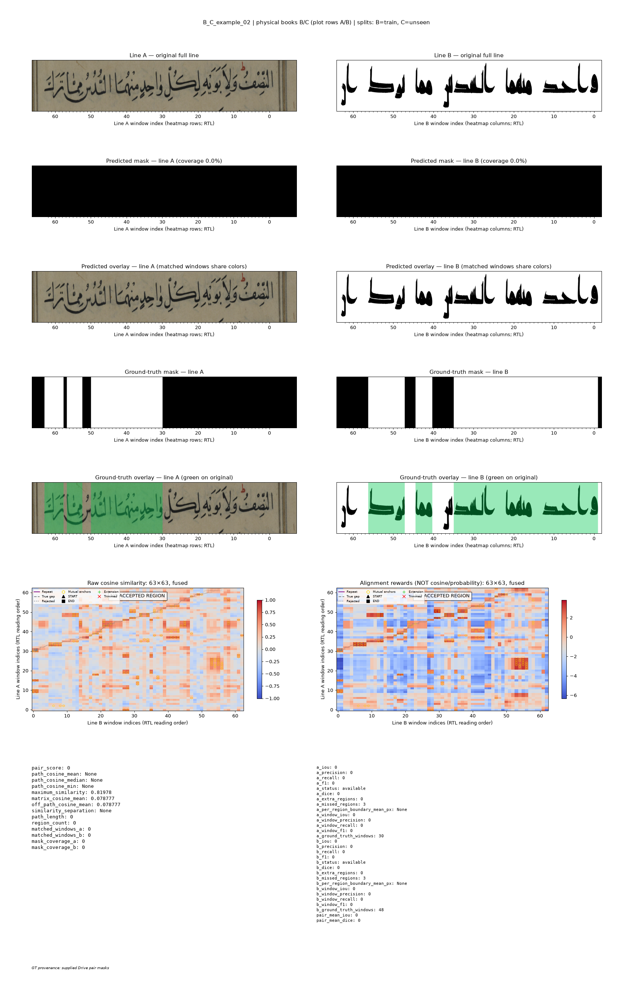

In [ ]:
from IPython.display import Image, display
print('B_C_example_02 | physical books B/C (plot rows A/B) | splits: B=train, C=unseen\nIoU: B=0.000, C=0.000; accepted routes=0\nMean mask IoU=0.000\nWhite-mask precision: B=0.000, C=0.000; recall: B=0.000, C=0.000\nPredicted white coverage: B=0.0%, C=0.0%\nBlack-background specificity: B=1.000, C=1.000\nWhite F2 (recall priority): B=0.000, C=0.000')
display(Image(filename=str(REVIEW / 'B_C_example_02.png')))


B_C_example_03 | physical books B/C (plot rows A/B) | splits: B=train, C=train
IoU: B=0.680, C=0.614; accepted routes=1
Mean mask IoU=0.647
White-mask precision: B=1.000, C=1.000; recall: B=0.680, C=0.614
Predicted white coverage: B=39.6%, C=43.2%
Black-background specificity: B=1.000, C=1.000
White F2 (recall priority): B=0.726, C=0.665


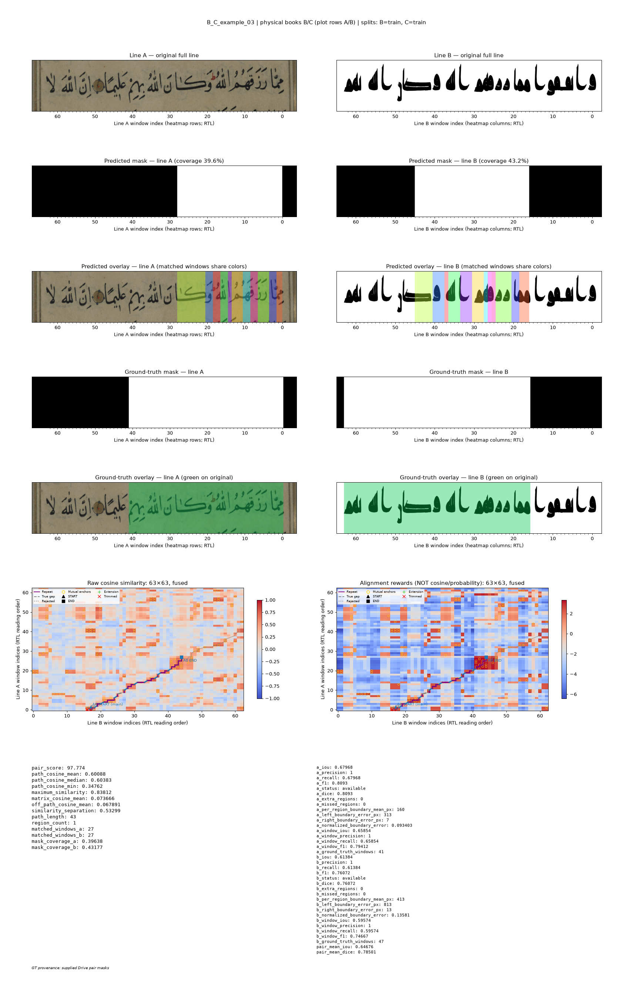

In [ ]:
from IPython.display import Image, display
print('B_C_example_03 | physical books B/C (plot rows A/B) | splits: B=train, C=train\nIoU: B=0.680, C=0.614; accepted routes=1\nMean mask IoU=0.647\nWhite-mask precision: B=1.000, C=1.000; recall: B=0.680, C=0.614\nPredicted white coverage: B=39.6%, C=43.2%\nBlack-background specificity: B=1.000, C=1.000\nWhite F2 (recall priority): B=0.726, C=0.665')
display(Image(filename=str(REVIEW / 'B_C_example_03.png')))


B_C_example_04 | physical books B/C (plot rows A/B) | splits: B=train, C=unseen
IoU: B=0.227, C=0.281; accepted routes=1
Mean mask IoU=0.254
White-mask precision: B=0.822, C=0.965; recall: B=0.239, C=0.284
Predicted white coverage: B=14.5%, C=21.2%
Black-background specificity: B=0.948, C=0.973
White F2 (recall priority): B=0.279, C=0.330


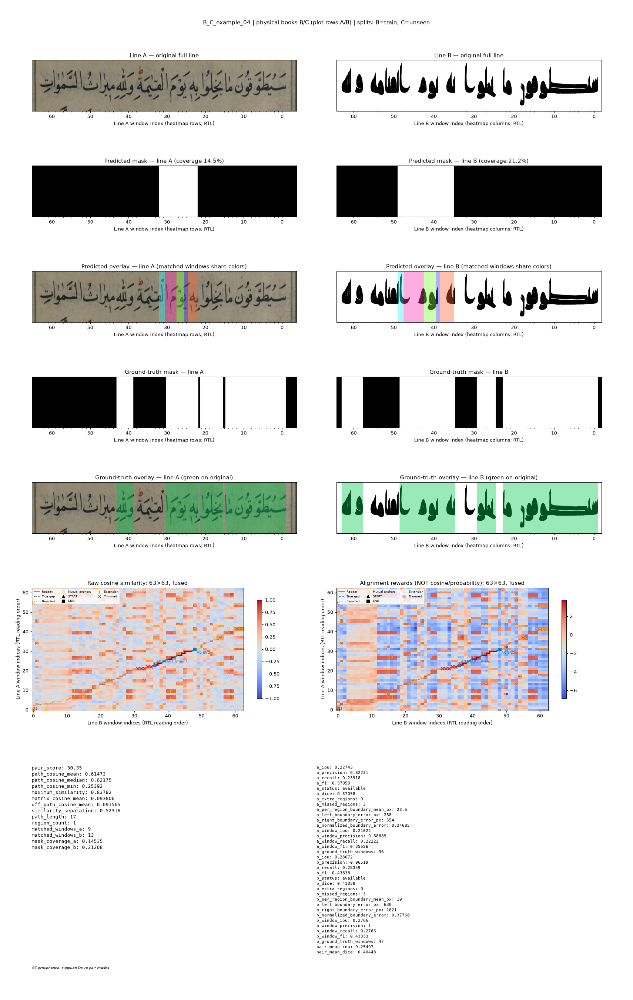

In [ ]:
from IPython.display import Image, display
print('B_C_example_04 | physical books B/C (plot rows A/B) | splits: B=train, C=unseen\nIoU: B=0.227, C=0.281; accepted routes=1\nMean mask IoU=0.254\nWhite-mask precision: B=0.822, C=0.965; recall: B=0.239, C=0.284\nPredicted white coverage: B=14.5%, C=21.2%\nBlack-background specificity: B=0.948, C=0.973\nWhite F2 (recall priority): B=0.279, C=0.330')
display(Image(filename=str(REVIEW / 'B_C_example_04.png')))


B_C_example_05 | physical books B/C (plot rows A/B) | splits: B=train, C=test
IoU: B=0.000, C=0.000; accepted routes=0
Mean mask IoU=0.000
White-mask precision: B=0.000, C=0.000; recall: B=0.000, C=0.000
Predicted white coverage: B=0.0%, C=0.0%
Black-background specificity: B=1.000, C=1.000
White F2 (recall priority): B=0.000, C=0.000


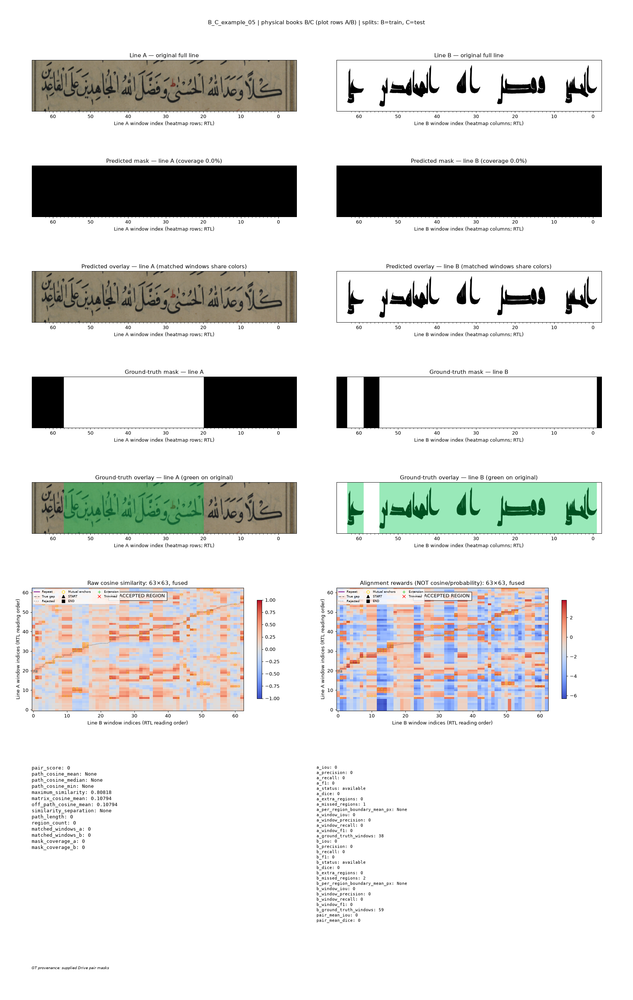

In [ ]:
from IPython.display import Image, display
print('B_C_example_05 | physical books B/C (plot rows A/B) | splits: B=train, C=test\nIoU: B=0.000, C=0.000; accepted routes=0\nMean mask IoU=0.000\nWhite-mask precision: B=0.000, C=0.000; recall: B=0.000, C=0.000\nPredicted white coverage: B=0.0%, C=0.0%\nBlack-background specificity: B=1.000, C=1.000\nWhite F2 (recall priority): B=0.000, C=0.000')
display(Image(filename=str(REVIEW / 'B_C_example_05.png')))
